# Aircraft Rotation Delay Analytics
### Turnaround propagation, hub misconnections and the cost of delay for a daily A320 rotation

**Context.** Consulting-style case study for a fictional German hub carrier ("Aerogermania", hub: Munich/MUC).
The COO proposes adding **+10 minutes of ground time to every turnaround** to improve punctuality.
This notebook tests that idea using one operated A320 rotation (7 flights) and 18 onward connections at the hub.

**Questions answered**

1. Where in the rotation does delay originate, and where does it propagate?
2. When does an arrival delay *force* a departure delay on the next leg, given a 40-minute minimum ground time (minGT)?
3. How many connecting passengers misconnect at the hub under minimum-connection-time (MCT) rules?
4. What does the rotation's delay cost, by category, and what would the blanket +10-minute buffer return?
5. What would a predictive delay model need, and what can (and cannot) be learned from 7 observations?

**Approach:** feature engineering on timestamps → rotation Gantt and delay diagnostics → exact minGT propagation logic →
MCT-based misconnection model → transparent, parameterised cost model → scenario simulation → leave-one-out ML pipeline
as a scaled-down template for production.

> **Data note.** All flights, passenger counts and cost parameters come from a fictional case-study dataset and do not
> describe a real airline. With n = 7 flights, the ML section demonstrates the pipeline, not predictive performance.

## 0. Setup

In [1]:
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
from matplotlib.patches import Patch

from sklearn.compose import ColumnTransformer
from sklearn.dummy import DummyClassifier, DummyRegressor
from sklearn.ensemble import RandomForestClassifier, RandomForestRegressor
from sklearn.metrics import accuracy_score, mean_absolute_error
from sklearn.model_selection import LeaveOneOut, cross_val_predict
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler

pd.set_option("display.max_columns", 80)
pd.set_option("display.width", 160)

# Paths work whether the notebook is run from the repo root or from notebooks/
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
DATA_DIR = ROOT / "data"
FIG_DIR = ROOT / "figures"
FIG_DIR.mkdir(exist_ok=True)

# Operational rules from the case
MIN_GT = 40                   # A320 minimum ground time, min
OTP_THRESHOLD = 15            # on-time performance threshold, min
MCT_CONTINENTAL = 45          # minimum connection time, flights < 3,500 km
MCT_INTERCONTINENTAL = 60     # minimum connection time, flights > 3,500 km
INTERCONTINENTAL_DESTINATIONS = {"JFK", "HND", "PVG", "JNB", "CPT", "LAX"}

In [2]:
# One visual language for every chart
GREEN, RED, BLUE, ORANGE, GREY = "#2ECC71", "#E74C3C", "#3498DB", "#F39C12", "#95A5A6"
SCHEDULED_GREY = "#D9DEE3"
TEXT = "#2C3E50"
SUBTLE = "#5D6D7E"
GRID = "#E6E9ED"
STATUS_COLORS = {1: GREEN, 0: RED}   # 1 = on time, 0 = delayed

plt.rcParams.update({
    "figure.facecolor": "white",
    "axes.facecolor": "white",
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.spines.left": False,
    "axes.edgecolor": "#AAB2BD",
    "axes.labelcolor": TEXT,
    "axes.labelsize": 11,
    "axes.grid": True,
    "axes.grid.axis": "y",
    "axes.axisbelow": True,
    "grid.color": GRID,
    "xtick.color": TEXT,
    "ytick.color": TEXT,
    "xtick.labelsize": 10,
    "ytick.labelsize": 10,
    "legend.frameon": False,
    "font.family": "sans-serif",
    "figure.dpi": 110,
})


def headline(ax, title, subtitle=None):
    """Left-aligned action title with optional subtitle, consulting-slide style."""
    ax.set_title(title, loc="left", fontsize=14, fontweight="bold", color=TEXT, pad=24 if subtitle else 12)
    if subtitle:
        ax.text(0, 1.025, subtitle, transform=ax.transAxes, fontsize=10, color=SUBTLE)


def eur(value):
    """Format euros with a proper minus sign: -1275 -> '−€1,275'."""
    return f"{'−' if value < 0 else ''}€{abs(value):,.0f}"


def savefig(fig, name):
    path = FIG_DIR / name
    fig.savefig(path, dpi=200, bbox_inches="tight")
    print(f"Saved: {path.relative_to(ROOT)}")

## 1. Data and feature engineering

Two tables:

* `data/rotation.csv`: one row per flight of the A320's day (scheduled/actual times, passengers split economy/business).
* `data/connections.csv`: onward connections at MUC fed by the three inbound hub flights.

Passenger fields come as `"economy/business"` strings, and the last flight lands after midnight, so timestamps need a day roll-over.

In [3]:
def parse_timestamp(date_str, time_str):
    return pd.to_datetime(f"{date_str} {time_str}")


def split_pax(value):
    """'130/8' -> (130, 8); missing -> (0, 0)."""
    if pd.isna(value) or value == "/":
        return pd.Series([0, 0])
    eco, bus = str(value).split("/")
    return pd.Series([int(eco), int(bus)])


df = pd.read_csv(DATA_DIR / "rotation.csv", dtype=str)

for col in ["std", "atd", "sta", "ata"]:
    df[f"{col}_dt"] = [parse_timestamp(d, t) for d, t in zip(df["date"], df[col])]

# After-midnight arrivals belong to the next calendar day
df.loc[df["ata_dt"] < df["std_dt"], "ata_dt"] += pd.Timedelta(days=1)
df.loc[df["sta_dt"] < df["std_dt"], "sta_dt"] += pd.Timedelta(days=1)

df["dep_delay_min"] = (df["atd_dt"] - df["std_dt"]).dt.total_seconds() / 60
df["arr_delay_min"] = (df["ata_dt"] - df["sta_dt"]).dt.total_seconds() / 60
df["delay_above_15_min"] = np.maximum(df["arr_delay_min"] - OTP_THRESHOLD, 0)

df[["direct_eco", "direct_bus"]] = df["direct_pax_eco_bus"].apply(split_pax)
df[["connex_eco", "connex_bus"]] = df["ob_connex_pax_eco_bus"].apply(split_pax)
df["direct_pax"] = df["direct_eco"] + df["direct_bus"]
df["connex_pax"] = df["connex_eco"] + df["connex_bus"]
df["total_pax"] = df["direct_pax"] + df["connex_pax"]

df["on_time_arrival_15"] = (df["arr_delay_min"] <= OTP_THRESHOLD).astype(int)
df["status"] = np.where(df["on_time_arrival_15"] == 1, "On time", "Delayed")
df["route"] = df["origin"] + "–" + df["destination"]

df[["flight_no", "route", "std", "atd", "sta", "ata",
    "dep_delay_min", "arr_delay_min", "direct_pax", "connex_pax", "total_pax", "status"]]

,flight_no,route,std,atd,sta,ata,dep_delay_min,arr_delay_min,direct_pax,connex_pax,total_pax,status
0,AEG111,MUC–GVA,07:00,07:10,08:05,08:15,10.0,10.0,138,0,138,On time
1,AEG112,GVA–MUC,08:50,09:10,09:55,10:15,20.0,20.0,44,85,129,Delayed
2,AEG201,MUC–PMI,11:00,11:15,12:30,12:45,15.0,15.0,103,0,103,On time
3,AEG202,PMI–MUC,13:30,14:00,15:00,15:30,30.0,30.0,94,12,106,Delayed
4,AEG501,MUC–AMS,16:30,16:35,18:30,18:35,5.0,5.0,160,0,160,On time
5,AEG502,AMS–MUC,19:30,19:55,21:35,22:00,25.0,25.0,149,31,180,Delayed
6,AEG301,MUC–CPH,22:20,22:45,23:45,00:10,25.0,25.0,87,0,87,Delayed


In [4]:
otp = df["on_time_arrival_15"].mean()
print(f"Flights: {len(df)} | On-time arrivals (≤{OTP_THRESHOLD} min): {df['on_time_arrival_15'].sum()}/{len(df)} = {otp:.0%}")
print(f"Total arrival delay: {df['arr_delay_min'].sum():.0f} min | Passengers carried: {df['total_pax'].sum():,}")

Flights: 7 | On-time arrivals (≤15 min): 3/7 = 43%
Total arrival delay: 130 min | Passengers carried: 903


## 2. The rotation at a glance

Grey bars show the scheduled block (STD→STA). Coloured bars show what was actually flown (ATD→ATA). Red marks an arrival more than 15 minutes late.

Saved: figures/fig_01_rotation_gantt.png


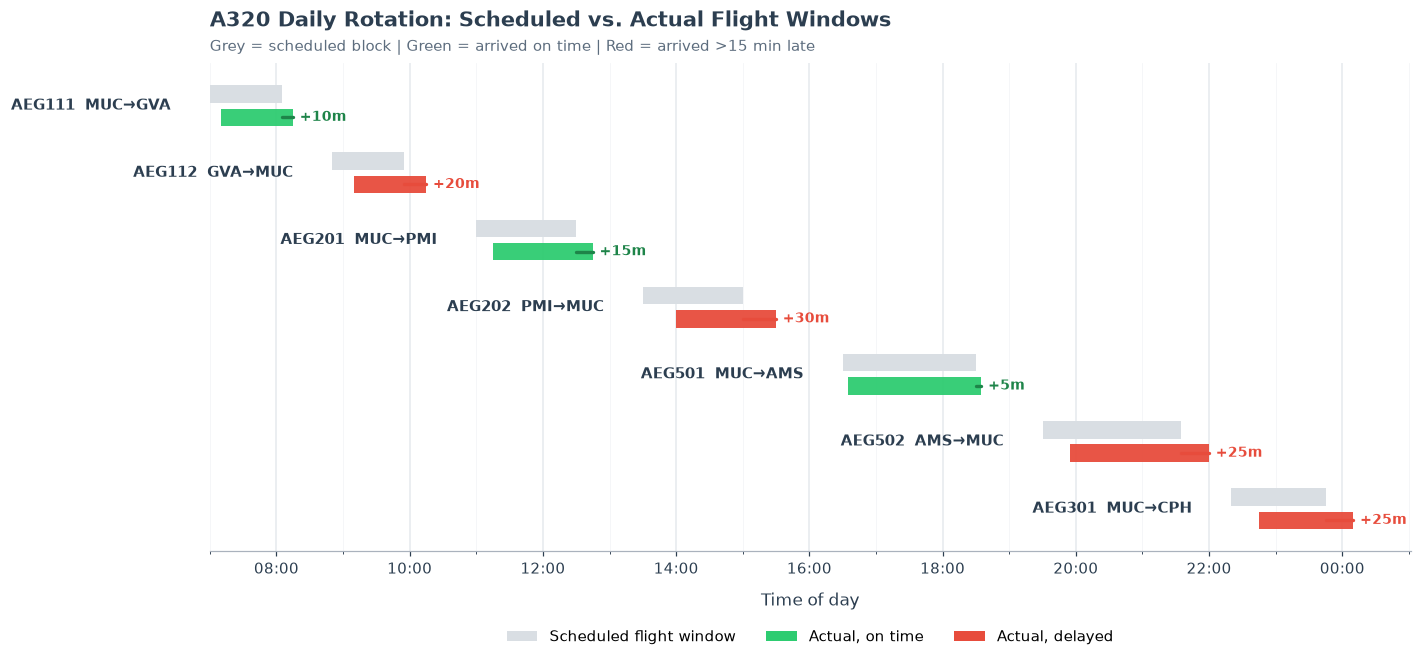

In [5]:
fig, ax = plt.subplots(figsize=(13, 6.2))
y_positions = np.arange(len(df))[::-1]
bar_h = 0.26

for i, row in df.iterrows():
    y = y_positions[i]
    actual_color = GREEN if row["on_time_arrival_15"] == 1 else RED

    ax.barh(y + bar_h / 1.5, row["sta_dt"] - row["std_dt"], left=row["std_dt"],
            height=bar_h, color=SCHEDULED_GREY, edgecolor="none")
    ax.barh(y - bar_h / 1.5, row["ata_dt"] - row["atd_dt"], left=row["atd_dt"],
            height=bar_h, color=actual_color, edgecolor="none", alpha=0.95)

    if row["arr_delay_min"] > 0:
        label_color = RED if row["on_time_arrival_15"] == 0 else "#1E8449"
        ax.plot([row["sta_dt"], row["ata_dt"]], [y - bar_h / 1.5] * 2,
                color=label_color, linewidth=2.2, solid_capstyle="round")
        ax.text(row["ata_dt"] + pd.Timedelta(minutes=6), y - bar_h / 1.5,
                f"+{int(row['arr_delay_min'])}m", va="center", ha="left",
                fontsize=9, color=label_color, fontweight="bold")

    ax.text(row["std_dt"] - pd.Timedelta(minutes=35), y,
            f"{row['flight_no']}  {row['origin']}→{row['destination']}",
            va="center", ha="right", fontsize=10, color=TEXT, fontweight="bold")

ax.xaxis.set_major_formatter(mdates.DateFormatter("%H:%M"))
ax.xaxis.set_major_locator(mdates.HourLocator(interval=2))
ax.xaxis.set_minor_locator(mdates.HourLocator(interval=1))
ax.set_yticks([])
ax.grid(True, axis="x", which="major", color=GRID, linewidth=1)
ax.grid(True, axis="x", which="minor", color=GRID, linewidth=0.5, alpha=0.5)
ax.grid(False, axis="y")
ax.set_xlabel("Time of day", labelpad=10)

headline(ax, "A320 Daily Rotation: Scheduled vs. Actual Flight Windows",
         "Grey = scheduled block | Green = arrived on time | Red = arrived >15 min late")
ax.legend(handles=[Patch(facecolor=SCHEDULED_GREY, label="Scheduled flight window"),
                   Patch(facecolor=GREEN, label="Actual, on time"),
                   Patch(facecolor=RED, label="Actual, delayed")],
          loc="lower center", bbox_to_anchor=(0.5, -0.22), ncol=3, fontsize=10)

plt.tight_layout()
savefig(fig, "fig_01_rotation_gantt.png")
plt.show()

## 3. Delay development across the rotation

With only seven flights, every bar is labelled.

Saved: figures/fig_02_arrival_delay_by_flight.png


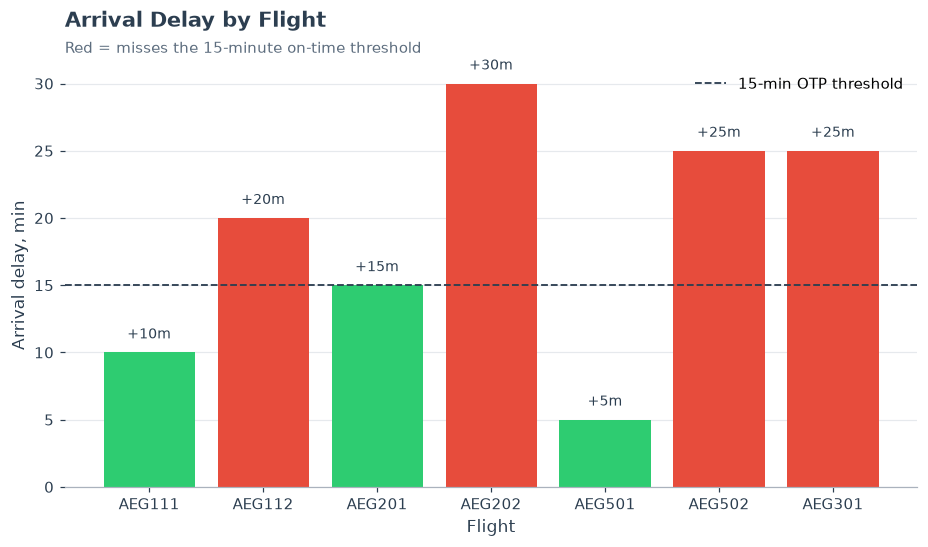

In [6]:
fig, ax = plt.subplots(figsize=(10, 5))
bars = ax.bar(df["flight_no"], df["arr_delay_min"], color=[STATUS_COLORS[x] for x in df["on_time_arrival_15"]])
ax.axhline(OTP_THRESHOLD, linestyle="--", color=TEXT, linewidth=1.2, label="15-min OTP threshold")
for bar, delay in zip(bars, df["arr_delay_min"]):
    ax.text(bar.get_x() + bar.get_width() / 2, bar.get_height() + 0.8, f"+{int(delay)}m",
            ha="center", va="bottom", fontsize=9, color=TEXT)
ax.set_xlabel("Flight")
ax.set_ylabel("Arrival delay, min")
headline(ax, "Arrival Delay by Flight", "Red = misses the 15-minute on-time threshold")
ax.legend()
savefig(fig, "fig_02_arrival_delay_by_flight.png")
plt.show()

Saved: figures/fig_03_delay_development.png


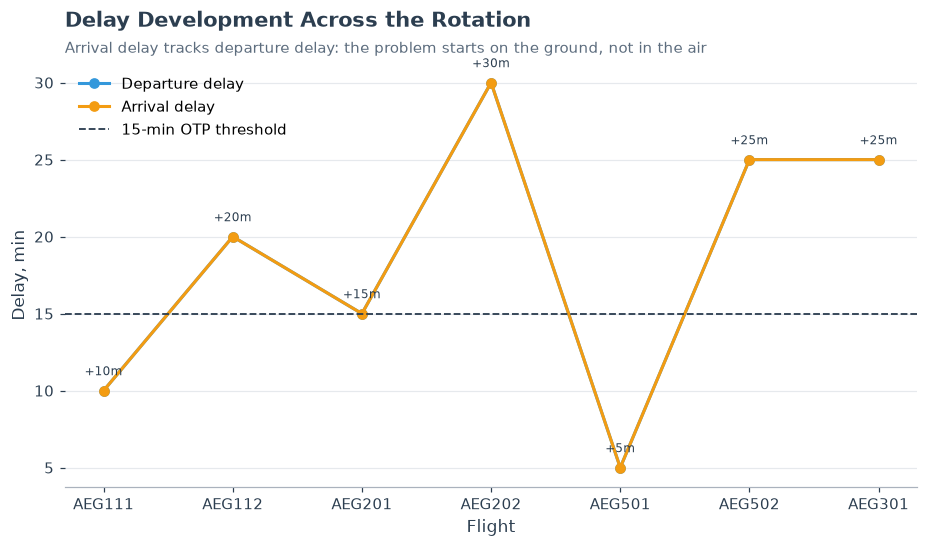

In [7]:
fig, ax = plt.subplots(figsize=(10, 5))
ax.plot(df["flight_no"], df["dep_delay_min"], marker="o", linewidth=2, label="Departure delay", color=BLUE)
ax.plot(df["flight_no"], df["arr_delay_min"], marker="o", linewidth=2, label="Arrival delay", color=ORANGE)
ax.axhline(OTP_THRESHOLD, linestyle="--", color=TEXT, linewidth=1.2, label="15-min OTP threshold")
for x, y in zip(df["flight_no"], df["arr_delay_min"]):
    ax.text(x, y + 1, f"+{int(y)}m", ha="center", fontsize=8, color=TEXT)
ax.set_xlabel("Flight")
ax.set_ylabel("Delay, min")
headline(ax, "Delay Development Across the Rotation",
         "Arrival delay tracks departure delay: the problem starts on the ground, not in the air")
ax.legend()
savefig(fig, "fig_03_delay_development.png")
plt.show()

## 4. Passenger exposure

Delay minutes matter more on flights that carry many passengers, and most of all connecting passengers, because they can misconnect.

Saved: figures/fig_04_passenger_exposure.png


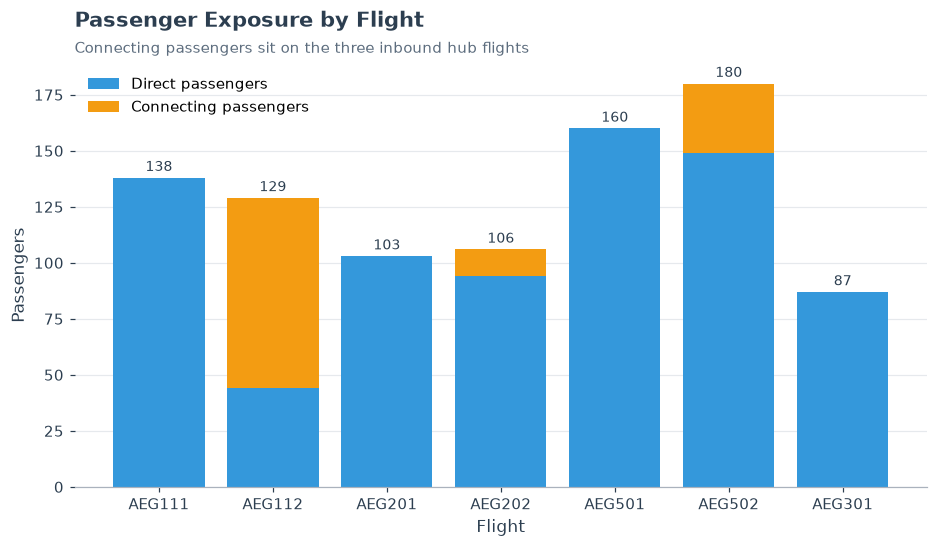

In [8]:
fig, ax = plt.subplots(figsize=(10, 5))
ax.bar(df["flight_no"], df["direct_pax"], label="Direct passengers", color=BLUE)
ax.bar(df["flight_no"], df["connex_pax"], bottom=df["direct_pax"], label="Connecting passengers", color=ORANGE)
for i, row in df.iterrows():
    ax.text(i, row["total_pax"] + 3, str(int(row["total_pax"])), ha="center", fontsize=9, color=TEXT)
ax.set_xlabel("Flight")
ax.set_ylabel("Passengers")
headline(ax, "Passenger Exposure by Flight", "Connecting passengers sit on the three inbound hub flights")
ax.legend()
savefig(fig, "fig_04_passenger_exposure.png")
plt.show()

Saved: figures/fig_05_delay_vs_passengers.png


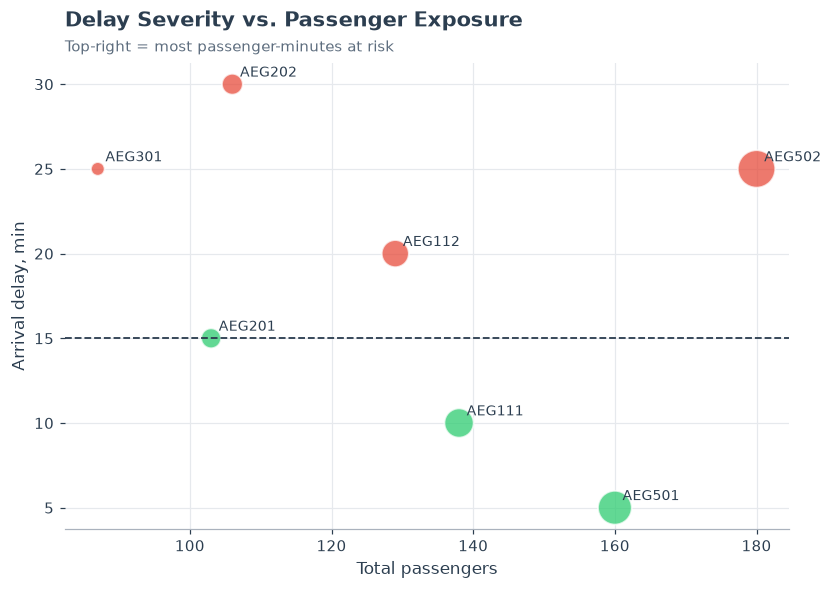

In [9]:
# Bubble size normalised to a visible range
min_size, max_size = 80, 600
pax = df["total_pax"].astype(float)
bubble_sizes = min_size + (pax - pax.min()) / (pax.max() - pax.min()) * (max_size - min_size)

fig, ax = plt.subplots(figsize=(8.5, 5.5))
ax.scatter(df["total_pax"], df["arr_delay_min"], s=bubble_sizes,
           color=[STATUS_COLORS[x] for x in df["on_time_arrival_15"]],
           alpha=0.75, edgecolors="white", linewidth=1.2)
for _, row in df.iterrows():
    ax.annotate(row["flight_no"], (row["total_pax"], row["arr_delay_min"]),
                xytext=(5, 5), textcoords="offset points", fontsize=9, color=TEXT)
ax.axhline(OTP_THRESHOLD, linestyle="--", color=TEXT, linewidth=1.2)
ax.grid(True, axis="both")
ax.set_xlabel("Total passengers")
ax.set_ylabel("Arrival delay, min")
headline(ax, "Delay Severity vs. Passenger Exposure", "Top-right = most passenger-minutes at risk")
savefig(fig, "fig_05_delay_vs_passengers.png")
plt.show()

## 5. Turnaround buffer and delay propagation

An arrival delay does not automatically become a departure delay on the next leg. It propagates only when it eats into the
40-minute minimum ground time:

```text
earliest feasible next departure      = actual arrival (ATA) + minGT
minimum unavoidable next-dep. delay   = max(0, earliest feasible next departure − next STD)
```

This splits the next leg's departure delay into two parts:

1. **minGT-forced delay**: unavoidable even with a perfect turnaround, caused structurally by the late inbound.
2. **Other delay**: what the turnaround itself added (ground handling, boarding, ATC slot, ...).

In [10]:
turns = df.iloc[:-1].copy().reset_index(drop=True)
nxt = df.iloc[1:].copy().reset_index(drop=True)

turns["next_flight"] = nxt["flight_no"]
turns["next_std_dt"] = nxt["std_dt"]
turns["next_atd_dt"] = nxt["atd_dt"]
turns["next_dep_delay_min"] = nxt["dep_delay_min"]
turns["turnaround"] = turns["flight_no"] + " → " + turns["next_flight"]

turns["scheduled_ground_time_min"] = (turns["next_std_dt"] - turns["sta_dt"]).dt.total_seconds() / 60
turns["actual_ground_time_min"] = (turns["next_atd_dt"] - turns["ata_dt"]).dt.total_seconds() / 60
turns["scheduled_buffer_vs_minGT"] = turns["scheduled_ground_time_min"] - MIN_GT
turns["actual_buffer_vs_minGT"] = turns["actual_ground_time_min"] - MIN_GT
turns["turnaround_risk"] = (turns["actual_buffer_vs_minGT"] < 0).astype(int)

# Core propagation logic
turns["earliest_feasible_next_dep_dt"] = turns["ata_dt"] + pd.Timedelta(minutes=MIN_GT)
turns["min_unavoidable_next_dep_delay_min"] = np.maximum(
    (turns["earliest_feasible_next_dep_dt"] - turns["next_std_dt"]).dt.total_seconds() / 60, 0
)
turns["other_next_dep_delay_min"] = np.maximum(
    turns["next_dep_delay_min"] - turns["min_unavoidable_next_dep_delay_min"], 0
)
# Share of the next leg's departure delay that is structurally forced (0 when there is no delay)
turns["share_explained_by_minGT"] = np.clip(
    np.divide(turns["min_unavoidable_next_dep_delay_min"], turns["next_dep_delay_min"],
              out=np.zeros(len(turns)), where=turns["next_dep_delay_min"] > 0),
    0, 1,
)
turns["delay_type"] = np.where(turns["min_unavoidable_next_dep_delay_min"] > 0,
                               "Propagated by arrival + minGT", "Absorbed by buffer / other cause")

view = pd.DataFrame({
    "turnaround": turns["turnaround"],
    "ATA": turns["ata_dt"].dt.strftime("%H:%M"),
    "next STD": turns["next_std_dt"].dt.strftime("%H:%M"),
    "earliest feasible dep.": turns["earliest_feasible_next_dep_dt"].dt.strftime("%H:%M"),
    "next ATD": turns["next_atd_dt"].dt.strftime("%H:%M"),
    "sched. GT": turns["scheduled_ground_time_min"].astype(int),
    "sched. buffer": turns["scheduled_buffer_vs_minGT"].astype(int),
    "actual GT": turns["actual_ground_time_min"].astype(int),
    "actual buffer": turns["actual_buffer_vs_minGT"].astype(int),
    "forced delay": turns["min_unavoidable_next_dep_delay_min"].astype(int),
    "next dep. delay": turns["next_dep_delay_min"].astype(int),
    "share forced": (turns["share_explained_by_minGT"] * 100).round().astype(int).astype(str) + "%",
    "delay type": turns["delay_type"],
})
view

,turnaround,ATA,next STD,earliest feasible dep.,next ATD,sched. GT,sched. buffer,actual GT,actual buffer,forced delay,next dep. delay,share forced,delay type
0,AEG111 → AEG112,08:15,08:50,08:55,09:10,45,5,55,15,5,20,25%,Propagated by arrival + minGT
1,AEG112 → AEG201,10:15,11:00,10:55,11:15,65,25,60,20,0,15,0%,Absorbed by buffer / other cause
2,AEG201 → AEG202,12:45,13:30,13:25,14:00,60,20,75,35,0,30,0%,Absorbed by buffer / other cause
3,AEG202 → AEG501,15:30,16:30,16:10,16:35,90,50,65,25,0,5,0%,Absorbed by buffer / other cause
4,AEG501 → AEG502,18:35,19:30,19:15,19:55,60,20,80,40,0,25,0%,Absorbed by buffer / other cause
5,AEG502 → AEG301,22:00,22:20,22:40,22:45,45,5,45,5,20,25,80%,Propagated by arrival + minGT


In [11]:
total_next_dep_delay = turns["next_dep_delay_min"].sum()
total_forced_delay = turns["min_unavoidable_next_dep_delay_min"].sum()
forced_share = total_forced_delay / total_next_dep_delay if total_next_dep_delay > 0 else 0
most_critical = turns.sort_values("min_unavoidable_next_dep_delay_min", ascending=False).iloc[0]

print(f"Next-leg departure delay across all turnarounds: {total_next_dep_delay:.0f} min")
print(f"  of which forced by late arrival + {MIN_GT}-min minGT: {total_forced_delay:.0f} min ({forced_share:.0%})")
print(f"Most critical turnaround: {most_critical['turnaround']} "
      f"({most_critical['min_unavoidable_next_dep_delay_min']:.0f} min forced of "
      f"{most_critical['next_dep_delay_min']:.0f} min actual)")

Next-leg departure delay across all turnarounds: 120 min
  of which forced by late arrival + 40-min minGT: 25 min (21%)
Most critical turnaround: AEG502 → AEG301 (20 min forced of 25 min actual)


Saved: figures/fig_06_mingt_forced_propagation.png


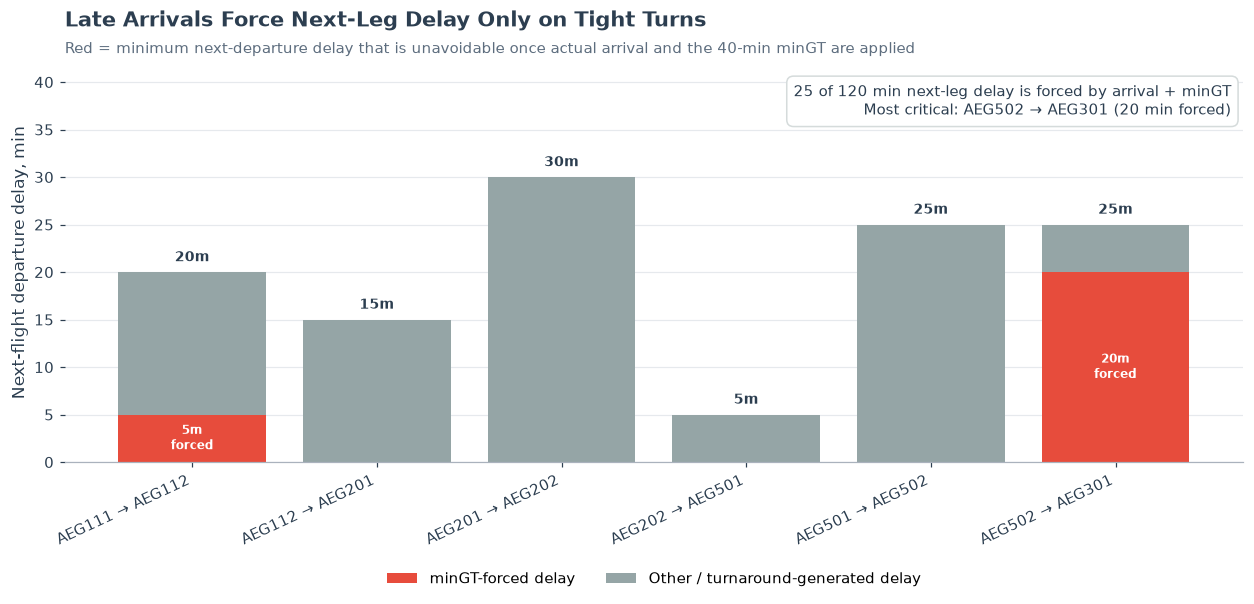

In [12]:
fig, ax = plt.subplots(figsize=(11.5, 5.8))
x = np.arange(len(turns))
ax.bar(x, turns["min_unavoidable_next_dep_delay_min"], color=RED, label="minGT-forced delay")
ax.bar(x, turns["other_next_dep_delay_min"], bottom=turns["min_unavoidable_next_dep_delay_min"],
       color=GREY, label="Other / turnaround-generated delay")

for i, row in turns.iterrows():
    total, forced = row["next_dep_delay_min"], row["min_unavoidable_next_dep_delay_min"]
    if total > 0:
        ax.text(i, total + 0.8, f"{int(total)}m", ha="center", va="bottom", fontsize=9, color=TEXT, fontweight="bold")
    if forced > 0:
        ax.text(i, forced / 2, f"{int(forced)}m\nforced", ha="center", va="center",
                fontsize=8, color="white", fontweight="bold")

ax.text(0.99, 0.95,
        f"{total_forced_delay:.0f} of {total_next_dep_delay:.0f} min next-leg delay is forced by arrival + minGT\n"
        f"Most critical: {most_critical['turnaround']} ({most_critical['min_unavoidable_next_dep_delay_min']:.0f} min forced)",
        transform=ax.transAxes, ha="right", va="top", fontsize=10, color=TEXT,
        bbox=dict(boxstyle="round,pad=0.45", facecolor="white", edgecolor="#D5DBDB"))

ax.set_ylim(0, turns["next_dep_delay_min"].max() * 1.4)   # headroom for the takeaway box
ax.set_xticks(x)
ax.set_xticklabels(turns["turnaround"], rotation=25, ha="right")
ax.set_ylabel("Next-flight departure delay, min")
headline(ax, "Late Arrivals Force Next-Leg Delay Only on Tight Turns",
         "Red = minimum next-departure delay that is unavoidable once actual arrival and the 40-min minGT are applied")
ax.legend(loc="upper center", bbox_to_anchor=(0.5, -0.24), ncol=2, fontsize=10)
plt.tight_layout()
savefig(fig, "fig_06_mingt_forced_propagation.png")
plt.show()

Saved: figures/fig_07_turnaround_buffer.png


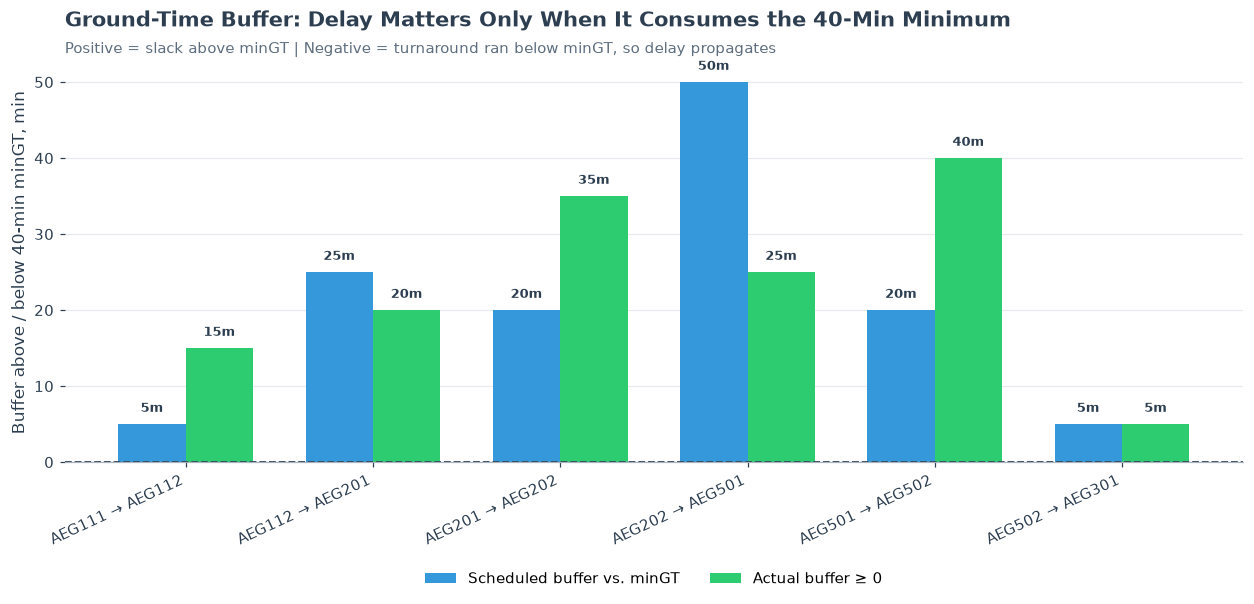

In [13]:
fig, ax = plt.subplots(figsize=(11.5, 5.8))
x = np.arange(len(turns))
w = 0.36
b_sched = ax.bar(x - w / 2, turns["scheduled_buffer_vs_minGT"], w, color=BLUE, label="Scheduled buffer vs. minGT")
b_act = ax.bar(x + w / 2, turns["actual_buffer_vs_minGT"], w,
               color=np.where(turns["actual_buffer_vs_minGT"] >= 0, GREEN, RED),
               label="Actual buffer vs. minGT")
ax.axhline(0, color=TEXT, linewidth=1.2, linestyle="--")

for bars in (b_sched, b_act):
    for bar in bars:
        val = bar.get_height()
        ax.text(bar.get_x() + bar.get_width() / 2, val + 1.2 if val >= 0 else val - 1.2, f"{int(val)}m",
                ha="center", va="bottom" if val >= 0 else "top", fontsize=8.5, color=TEXT, fontweight="bold")

ax.set_xticks(x)
ax.set_xticklabels(turns["turnaround"], rotation=25, ha="right")
ax.set_ylabel("Buffer above / below 40-min minGT, min")
headline(ax, "Ground-Time Buffer: Delay Matters Only When It Consumes the 40-Min Minimum",
         "Positive = slack above minGT | Negative = turnaround ran below minGT, so delay propagates")
handles = [Patch(facecolor=BLUE, label="Scheduled buffer vs. minGT"),
           Patch(facecolor=GREEN, label="Actual buffer ≥ 0")]
if (turns["actual_buffer_vs_minGT"] < 0).any():
    handles.append(Patch(facecolor=RED, label="Actual buffer < 0"))
ax.legend(handles=handles, loc="upper center", bbox_to_anchor=(0.5, -0.24), ncol=len(handles), fontsize=10)
plt.tight_layout()
savefig(fig, "fig_07_turnaround_buffer.png")
plt.show()

**Interpretation.** Arrival delay is not the same as propagated delay. Delay only carries into the next leg when
`ATA + 40 min > next STD`. Some turns absorb inbound delay in their scheduled slack, while others have almost none.
A **targeted** robustness approach therefore beats a uniform buffer: protect the few turns where arrival delay
directly forces next-leg delay, and treat the turnaround-generated part (grey) as a ground-process problem.

## 6. Hub connections and misconnections

A connection breaks when the time between the inbound's **actual** arrival and the outbound's scheduled departure is shorter than the MCT:
**45 min** for continental and **60 min** for intercontinental (> 3,500 km) outbounds. Destinations are classified with a lookup set, which is enough for this route list.

In [14]:
conn = pd.read_csv(DATA_DIR / "connections.csv", dtype=str)
conn[["connex_eco", "connex_bus"]] = conn["connex_pax_eco_bus"].apply(split_pax)
conn["connex_pax"] = conn["connex_eco"] + conn["connex_bus"]
conn["outbound_std_dt"] = [parse_timestamp(d, t) for d, t in zip(conn["inbound_date"], conn["outbound_std"])]

# Actual inbound arrival comes from the rotation table
conn = conn.merge(df[["flight_no", "ata_dt", "sta_dt", "arr_delay_min"]],
                  left_on="inbound_flight_no", right_on="flight_no", how="left").drop(columns="flight_no")

conn["is_intercontinental"] = conn["outbound_to"].isin(INTERCONTINENTAL_DESTINATIONS).astype(int)
conn["mct_min"] = np.where(conn["is_intercontinental"] == 1, MCT_INTERCONTINENTAL, MCT_CONTINENTAL)
conn["available_connect_time_min"] = (conn["outbound_std_dt"] - conn["ata_dt"]).dt.total_seconds() / 60
conn["misconnected"] = (conn["available_connect_time_min"] < conn["mct_min"]).astype(int)
conn["misconnected_pax"] = conn["misconnected"] * conn["connex_pax"]

conn[["inbound_flight_no", "outbound_flight_no", "outbound_to", "connex_pax", "ata_dt", "outbound_std",
      "available_connect_time_min", "mct_min", "misconnected", "misconnected_pax"]]

,inbound_flight_no,outbound_flight_no,outbound_to,connex_pax,ata_dt,outbound_std,available_connect_time_min,mct_min,misconnected,misconnected_pax
0,AEG112,AEG301,CPH,18,2026-03-20 10:15:00,10:50,35.0,45,1,18
1,AEG112,AEG302,LHR,17,2026-03-20 10:15:00,11:00,45.0,45,0,0
2,AEG112,AEG303,CDG,12,2026-03-20 10:15:00,11:20,65.0,45,0,0
3,AEG112,AEG304,FRA,17,2026-03-20 10:15:00,11:40,85.0,45,0,0
4,AEG112,AEG305,JFK,11,2026-03-20 10:15:00,11:00,45.0,60,1,11
5,AEG112,AEG306,HND,10,2026-03-20 10:15:00,12:20,125.0,60,0,0
6,AEG202,AEG307,HAM,2,2026-03-20 15:30:00,15:45,15.0,45,1,2
7,AEG202,AEG308,ZRH,2,2026-03-20 15:30:00,16:00,30.0,45,1,2
8,AEG202,AEG309,FCO,2,2026-03-20 15:30:00,16:15,45.0,45,0,0
9,AEG202,AEG310,DUS,2,2026-03-20 15:30:00,16:30,60.0,45,0,0


In [15]:
misconn_summary = conn.groupby("inbound_flight_no", as_index=False).agg(
    total_connecting_pax=("connex_pax", "sum"),
    misconnected_pax=("misconnected_pax", "sum"),
    missed_connections=("misconnected", "sum"),
)
misconn_summary["misconnection_rate"] = misconn_summary["misconnected_pax"] / misconn_summary["total_connecting_pax"]
misconn_summary

,inbound_flight_no,total_connecting_pax,misconnected_pax,missed_connections,misconnection_rate
0,AEG112,85,29,2,0.341176
1,AEG202,12,4,2,0.333333
2,AEG502,31,26,5,0.838710


Saved: figures/fig_08_misconnected_pax.png


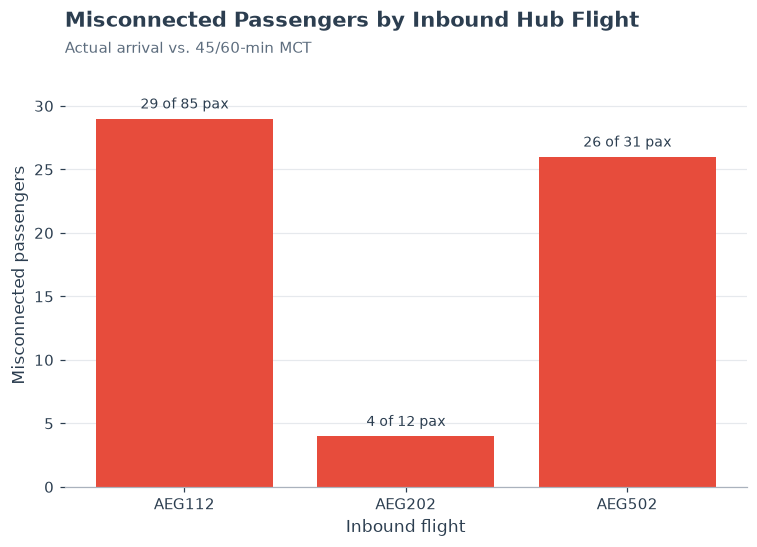

In [16]:
fig, ax = plt.subplots(figsize=(8, 5))
bars = ax.bar(misconn_summary["inbound_flight_no"], misconn_summary["misconnected_pax"], color=RED)
for bar, val, tot in zip(bars, misconn_summary["misconnected_pax"], misconn_summary["total_connecting_pax"]):
    ax.text(bar.get_x() + bar.get_width() / 2, bar.get_height() + 0.8, f"{int(val)} of {int(tot)} pax",
            ha="center", fontsize=9, color=TEXT)
ax.set_ylim(0, misconn_summary["misconnected_pax"].max() * 1.15)
ax.set_xlabel("Inbound flight")
ax.set_ylabel("Misconnected passengers")
headline(ax, "Misconnected Passengers by Inbound Hub Flight", "Actual arrival vs. 45/60-min MCT")
savefig(fig, "fig_08_misconnected_pax.png")
plt.show()

## 7. Cost of delay

A deliberately transparent, parameterised model. Every assumption sits in one dictionary, so a stakeholder can challenge and change it.

| Level | Components |
|---|---|
| Flight | operational cost per delay minute, direct and connecting passenger inconvenience above 15 min, fuel for high-speed recovery, ground-handling surcharge by delay band, crew-standby proxy |
| Connection | claim processing, meal vouchers, security re-screening, hotels, rebooking (continental / intercontinental), travel-insurance payouts |

In [17]:
ASSUMPTIONS = {
    "operational_cost_per_arr_delay_min": 75,
    "direct_pax_cost_per_delay_min_above_15": 5,
    "connex_pax_cost_per_delay_min_above_15": 20,
    "fuel_high_speed_cruise_cost_per_delay_min": 5,
    "claim_processing_fee_per_claim": 10,
    "meal_voucher": 10,
    "meal_take_rate": 0.30,
    "security_screening_fee": 5,
    "hotel_cost": 120,
    "hotel_take_rate": 0.25,
    "rebooking_cost_continental": 100,
    "rebooking_cost_intercontinental": 300,
    "insurance_payout_per_insured_pax": 200,
    "insurance_take_rate": 0.05,
    "cabin_fte_cost_per_day": 300,
    "cockpit_fte_cost_per_day": 1000,
    "cabin_fte_per_reduced_arr_delay_min": 0.0034,
    "cockpit_fte_per_reduced_arr_delay_min": 0.0004,
}


def ground_surcharge(delay_min):
    """Ground-handling surcharge (EUR) by arrival-delay band."""
    if delay_min <= 0:
        return 0
    if delay_min <= 30:
        return 50
    if delay_min <= 60:
        return 80
    if delay_min <= 120:
        return 140
    return 200


A = ASSUMPTIONS
df["cost_operational_delay"] = df["arr_delay_min"] * A["operational_cost_per_arr_delay_min"]
df["cost_direct_pax_delay"] = df["delay_above_15_min"] * df["direct_pax"] * A["direct_pax_cost_per_delay_min_above_15"]
df["cost_connex_pax_delay"] = df["delay_above_15_min"] * df["connex_pax"] * A["connex_pax_cost_per_delay_min_above_15"]
df["cost_fuel_recovery"] = df["arr_delay_min"] * A["fuel_high_speed_cruise_cost_per_delay_min"]
df["cost_ground_surcharge"] = df["arr_delay_min"].apply(ground_surcharge)
# Crew-standby proxy from the case's linear standby functions
# (cabin: Y = -0.0034x + 146, cockpit: Y = -0.0004x + 8, x = arrival delay minutes)
df["cost_cabin_standby_proxy"] = df["arr_delay_min"] * A["cabin_fte_per_reduced_arr_delay_min"] * A["cabin_fte_cost_per_day"]
df["cost_cockpit_standby_proxy"] = df["arr_delay_min"] * A["cockpit_fte_per_reduced_arr_delay_min"] * A["cockpit_fte_cost_per_day"]

flight_cost_cols = ["cost_operational_delay", "cost_direct_pax_delay", "cost_connex_pax_delay", "cost_fuel_recovery",
                    "cost_ground_surcharge", "cost_cabin_standby_proxy", "cost_cockpit_standby_proxy"]
df["flight_delay_cost"] = df[flight_cost_cols].sum(axis=1)
df[["flight_no", "arr_delay_min"] + flight_cost_cols + ["flight_delay_cost"]].round(1)

,flight_no,arr_delay_min,cost_operational_delay,cost_direct_pax_delay,cost_connex_pax_delay,cost_fuel_recovery,cost_ground_surcharge,cost_cabin_standby_proxy,cost_cockpit_standby_proxy,flight_delay_cost
0,AEG111,10.0,750.0,0.0,0.0,50.0,50,10.2,4.0,864.2
1,AEG112,20.0,1500.0,1100.0,8500.0,100.0,50,20.4,8.0,11278.4
2,AEG201,15.0,1125.0,0.0,0.0,75.0,50,15.3,6.0,1271.3
3,AEG202,30.0,2250.0,7050.0,3600.0,150.0,50,30.6,12.0,13142.6
4,AEG501,5.0,375.0,0.0,0.0,25.0,50,5.1,2.0,457.1
5,AEG502,25.0,1875.0,7450.0,6200.0,125.0,50,25.5,10.0,15735.5
6,AEG301,25.0,1875.0,4350.0,0.0,125.0,50,25.5,10.0,6435.5


In [18]:
conn["rebooking_cost"] = np.where(conn["is_intercontinental"] == 1,
                                  A["rebooking_cost_intercontinental"], A["rebooking_cost_continental"])
conn["cost_claim_processing"] = conn["misconnected_pax"] * A["claim_processing_fee_per_claim"]
conn["cost_meals"] = conn["misconnected_pax"] * A["meal_voucher"] * A["meal_take_rate"]
conn["cost_security"] = conn["misconnected_pax"] * A["security_screening_fee"]
conn["cost_hotels"] = conn["misconnected_pax"] * A["hotel_cost"] * A["hotel_take_rate"]
conn["cost_rebooking"] = conn["misconnected_pax"] * conn["rebooking_cost"]
conn["cost_insurance"] = conn["misconnected_pax"] * A["insurance_payout_per_insured_pax"] * A["insurance_take_rate"]

connection_cost_cols = ["cost_claim_processing", "cost_meals", "cost_security",
                        "cost_hotels", "cost_rebooking", "cost_insurance"]
conn["connection_disruption_cost"] = conn[connection_cost_cols].sum(axis=1)

conn.loc[conn["misconnected"] == 1,
         ["inbound_flight_no", "outbound_flight_no", "outbound_to", "misconnected_pax"]
         + connection_cost_cols + ["connection_disruption_cost"]]

,inbound_flight_no,outbound_flight_no,outbound_to,misconnected_pax,cost_claim_processing,cost_meals,cost_security,cost_hotels,cost_rebooking,cost_insurance,connection_disruption_cost
0,AEG112,AEG301,CPH,18,180,54.0,90,540.0,1800,180.0,2844.0
4,AEG112,AEG305,JFK,11,110,33.0,55,330.0,3300,110.0,3938.0
6,AEG202,AEG307,HAM,2,20,6.0,10,60.0,200,20.0,316.0
7,AEG202,AEG308,ZRH,2,20,6.0,10,60.0,200,20.0,316.0
12,AEG502,AEG313,ATH,6,60,18.0,30,180.0,600,60.0,948.0
13,AEG502,AEG314,JNB,7,70,21.0,35,210.0,2100,70.0,2506.0
14,AEG502,AEG315,OSL,6,60,18.0,30,180.0,600,60.0,948.0
15,AEG502,AEG316,IST,4,40,12.0,20,120.0,400,40.0,632.0
16,AEG502,AEG317,CPT,3,30,9.0,15,90.0,900,30.0,1074.0


In [19]:
flight_level_total = df["flight_delay_cost"].sum()
connection_level_total = conn["connection_disruption_cost"].sum()
total_rotation_cost = flight_level_total + connection_level_total

print(f"Flight-level delay cost:     €{flight_level_total:>9,.0f}")
print(f"Connection disruption cost:  €{connection_level_total:>9,.0f}")
print(f"Total rotation cost (1 day): €{total_rotation_cost:>9,.0f}")

Flight-level delay cost:     €   49,185
Connection disruption cost:  €   13,522
Total rotation cost (1 day): €   62,707


Saved: figures/fig_09_cost_by_category.png


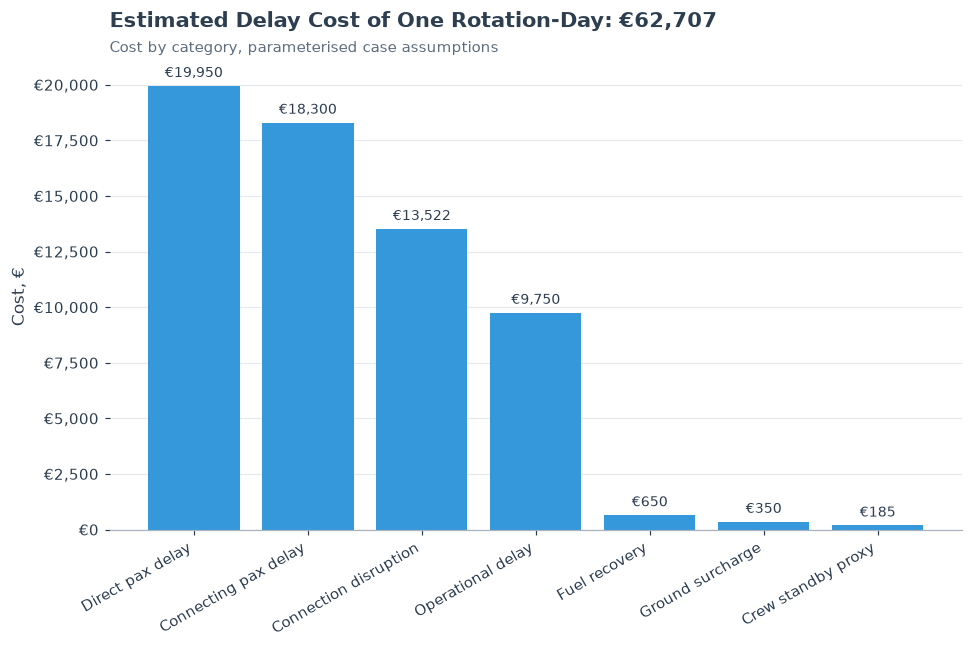

,cost_eur
Direct pax delay,19950.0
Connecting pax delay,18300.0
Connection disruption,13522.0
Operational delay,9750.0
Fuel recovery,650.0
Ground surcharge,350.0
Crew standby proxy,185.0


In [20]:
cost_summary = pd.Series({
    "Operational delay": df["cost_operational_delay"].sum(),
    "Direct pax delay": df["cost_direct_pax_delay"].sum(),
    "Connecting pax delay": df["cost_connex_pax_delay"].sum(),
    "Fuel recovery": df["cost_fuel_recovery"].sum(),
    "Ground surcharge": df["cost_ground_surcharge"].sum(),
    "Crew standby proxy": df["cost_cabin_standby_proxy"].sum() + df["cost_cockpit_standby_proxy"].sum(),
    "Connection disruption": conn["connection_disruption_cost"].sum(),
}).sort_values(ascending=False)

fig, ax = plt.subplots(figsize=(10, 5.5))
bars = ax.bar(cost_summary.index, cost_summary.values, color=BLUE)
for bar, val in zip(bars, cost_summary.values):
    ax.text(bar.get_x() + bar.get_width() / 2, bar.get_height() + cost_summary.max() * 0.02,
            f"€{val:,.0f}", ha="center", fontsize=9, color=TEXT)
ax.tick_params(axis="x", rotation=30)
plt.setp(ax.get_xticklabels(), ha="right")
ax.set_ylabel("Cost, €")
ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f"€{v:,.0f}"))
headline(ax, f"Estimated Delay Cost of One Rotation-Day: €{total_rotation_cost:,.0f}",
         "Cost by category, parameterised case assumptions")
savefig(fig, "fig_09_cost_by_category.png")
plt.show()

cost_summary.to_frame("cost_eur").round(0)

## 8. Scenario: the COO's "+10 minutes ground time everywhere"

A first-order simulation built on the propagation logic from section 5:
* add 10 min to the scheduled ground time of every turnaround (each subsequent STD moves 10 min later),
* the minGT-forced delay of each turn falls to `max(0, forced − 10)`, so each turn can absorb at most 10 min,
* value absorbed minutes at the operational delay-cost rate and compare that with the opportunity cost of the extra block time.

This is not a schedule optimisation, and knock-on effects further down the rotation are ignored. It is enough to show whether a blanket buffer pays off.

In [21]:
BUFFER_ADD_MIN = 10
AIRCRAFT_OPPORTUNITY_COST_PER_MIN = 40   # EUR, placeholder for lost aircraft utilisation

scenario = turns[["turnaround", "scheduled_ground_time_min", "scheduled_buffer_vs_minGT"]].copy()
scenario["forced_delay_min"] = turns["min_unavoidable_next_dep_delay_min"]
scenario["scheduled_ground_time_plus10"] = scenario["scheduled_ground_time_min"] + BUFFER_ADD_MIN
scenario["forced_delay_after_plus10_min"] = np.maximum(scenario["forced_delay_min"] - BUFFER_ADD_MIN, 0)
scenario["absorbed_delay_min"] = scenario["forced_delay_min"] - scenario["forced_delay_after_plus10_min"]
scenario["unused_buffer_min"] = BUFFER_ADD_MIN - scenario["absorbed_delay_min"]
scenario["estimated_savings_eur"] = scenario["absorbed_delay_min"] * A["operational_cost_per_arr_delay_min"]
scenario

,turnaround,scheduled_ground_time_min,scheduled_buffer_vs_minGT,forced_delay_min,scheduled_ground_time_plus10,forced_delay_after_plus10_min,absorbed_delay_min,unused_buffer_min,estimated_savings_eur
0,AEG111 → AEG112,45.0,5.0,5.0,55.0,0.0,5.0,5.0,375.0
1,AEG112 → AEG201,65.0,25.0,0.0,75.0,0.0,0.0,10.0,0.0
2,AEG201 → AEG202,60.0,20.0,0.0,70.0,0.0,0.0,10.0,0.0
3,AEG202 → AEG501,90.0,50.0,0.0,100.0,0.0,0.0,10.0,0.0
4,AEG501 → AEG502,60.0,20.0,0.0,70.0,0.0,0.0,10.0,0.0
5,AEG502 → AEG301,45.0,5.0,20.0,55.0,10.0,10.0,0.0,750.0


In [22]:
scenario_savings = scenario["estimated_savings_eur"].sum()
added_buffer_min = BUFFER_ADD_MIN * len(scenario)
absorbed_min = scenario["absorbed_delay_min"].sum()
turns_benefiting = int((scenario["absorbed_delay_min"] > 0).sum())
scenario_added_cost = added_buffer_min * AIRCRAFT_OPPORTUNITY_COST_PER_MIN
scenario_net_impact = scenario_savings - scenario_added_cost

print(f"Added block time:                {added_buffer_min:>6.0f} min over {len(scenario)} turnarounds")
print(f"Forced delay absorbed:           {absorbed_min:>6.0f} min ({absorbed_min / added_buffer_min:.0%} of the added time)")
print(f"Turnarounds that benefit:        {turns_benefiting:>6d} of {len(scenario)}")
print(f"Savings from absorbed delay:     {eur(scenario_savings):>9}")
print(f"Opportunity cost of added time:  {eur(scenario_added_cost):>9}")
print(f"Net impact per rotation-day:     {eur(scenario_net_impact):>9}")

Added block time:                    60 min over 6 turnarounds
Forced delay absorbed:               15 min (25% of the added time)
Turnarounds that benefit:             2 of 6
Savings from absorbed delay:        €1,125
Opportunity cost of added time:     €2,400
Net impact per rotation-day:       −€1,275


Saved: figures/fig_10_coo_plus10_scenario.png


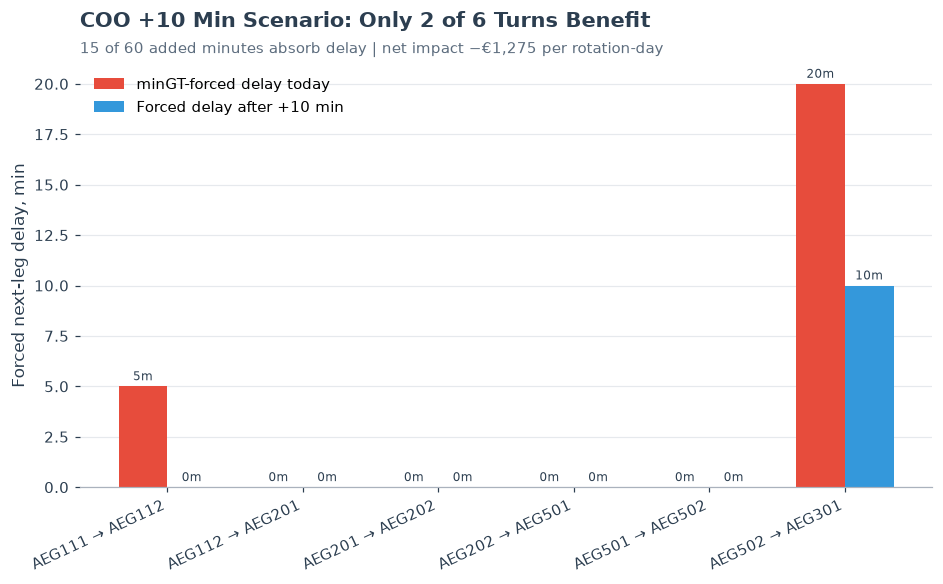

In [23]:
fig, ax = plt.subplots(figsize=(10, 5))
x = np.arange(len(scenario))
w = 0.36
b0 = ax.bar(x - w / 2, scenario["forced_delay_min"], w, label="minGT-forced delay today", color=RED)
b1 = ax.bar(x + w / 2, scenario["forced_delay_after_plus10_min"], w, label="Forced delay after +10 min", color=BLUE)
for bars in (b0, b1):
    for bar in bars:
        ax.text(bar.get_x() + bar.get_width() / 2, bar.get_height() + 0.3, f"{int(bar.get_height())}m",
                ha="center", fontsize=8, color=TEXT)
ax.set_xticks(x)
ax.set_xticklabels(scenario["turnaround"], rotation=25, ha="right")
ax.set_ylabel("Forced next-leg delay, min")
headline(ax, f"COO +10 Min Scenario: Only {turns_benefiting} of {len(scenario)} Turns Benefit",
         f"{absorbed_min:.0f} of {added_buffer_min:.0f} added minutes absorb delay | "
         f"net impact {eur(scenario_net_impact)} per rotation-day")
ax.legend()
savefig(fig, "fig_10_coo_plus10_scenario.png")
plt.show()

## 9. Network-wide proxy scaling

The sample rotation is scaled to the fleet (300 aircraft × 365 days). The sample day is a disrupted one,
so this is an **upper-bound** order of magnitude.
A real estimate needs all rotations and operating days, because delay distributions are heavily skewed.

In [24]:
FLEET_SIZE = 300
OPERATING_DAYS = 365

annual_network_cost = total_rotation_cost * FLEET_SIZE * OPERATING_DAYS
annual_network_plus10_impact = scenario_net_impact * FLEET_SIZE * OPERATING_DAYS

scaling_summary = pd.DataFrame({
    "metric": ["Rotation-day delay cost", "Network annual delay cost (proxy)",
               "Rotation-day net impact of +10 min", "Network annual impact of +10 min (proxy)"],
    "value_eur": [total_rotation_cost, annual_network_cost, scenario_net_impact, annual_network_plus10_impact],
})
scaling_summary.style.format({"value_eur": eur}).hide(axis="index")

metric,value_eur
Rotation-day delay cost,"€62,707"
Network annual delay cost (proxy),"€6,866,372,700"
Rotation-day net impact of +10 min,"−€1,275"
Network annual impact of +10 min (proxy),"−€139,612,500"


## 10. Machine learning: a pipeline template evaluated with leave-one-out

Seven rows cannot support a train/test split. Each prediction therefore comes from **leave-one-out (LOO)** cross-validation
(train on 6, predict the 7th), and every model is compared with a naive baseline. A model only adds value if it beats the baseline.

Features are known at or before departure: route, scheduled hours, passenger load and departure delay.
Departure delay is a legitimate feature for an *arrival*-delay forecast made at take-off.

In [25]:
ml_df = df.copy()
ml_df["std_hour"] = ml_df["std_dt"].dt.hour
ml_df["sta_hour"] = ml_df["sta_dt"].dt.hour

categorical_features = ["origin", "destination"]
numeric_features = ["std_hour", "sta_hour", "direct_pax", "connex_pax", "dep_delay_min"]
X = ml_df[categorical_features + numeric_features]
y_reg = ml_df["arr_delay_min"]
y_cls = ml_df["on_time_arrival_15"]

preprocess = ColumnTransformer([
    ("cat", OneHotEncoder(handle_unknown="ignore"), categorical_features),
    ("num", StandardScaler(), numeric_features),
])
loo = LeaveOneOut()

In [26]:
reg_model = Pipeline([("preprocess", preprocess),
                      ("model", RandomForestRegressor(n_estimators=300, random_state=42))])

ml_df["pred_arr_delay_loo"] = cross_val_predict(reg_model, X, y_reg, cv=loo)
ml_df["baseline_arr_delay_loo"] = cross_val_predict(DummyRegressor(strategy="mean"), X, y_reg, cv=loo)

rf_mae = mean_absolute_error(y_reg, ml_df["pred_arr_delay_loo"])
dummy_mae = mean_absolute_error(y_reg, ml_df["baseline_arr_delay_loo"])
print(f"LOO MAE, random forest:  {rf_mae:.1f} min")
print(f"LOO MAE, mean baseline:  {dummy_mae:.1f} min")
print("Caveat: n = 7. This demonstrates the pipeline, not real predictive skill.")

ml_df[["flight_no", "route", "arr_delay_min", "pred_arr_delay_loo", "baseline_arr_delay_loo"]].round(1)

LOO MAE, random forest:  6.5 min
LOO MAE, mean baseline:  8.6 min
Caveat: n = 7. This demonstrates the pipeline, not real predictive skill.


,flight_no,route,arr_delay_min,pred_arr_delay_loo,baseline_arr_delay_loo
0,AEG111,MUC–GVA,10.0,14.2,20.0
1,AEG112,GVA–MUC,20.0,18.8,18.3
2,AEG201,MUC–PMI,15.0,17.4,19.2
3,AEG202,PMI–MUC,30.0,20.2,16.7
4,AEG501,MUC–AMS,5.0,19.4,20.8
5,AEG502,AMS–MUC,25.0,19.8,17.5
6,AEG301,MUC–CPH,25.0,16.2,17.5


Saved: figures/fig_11_ml_actual_vs_predicted.png


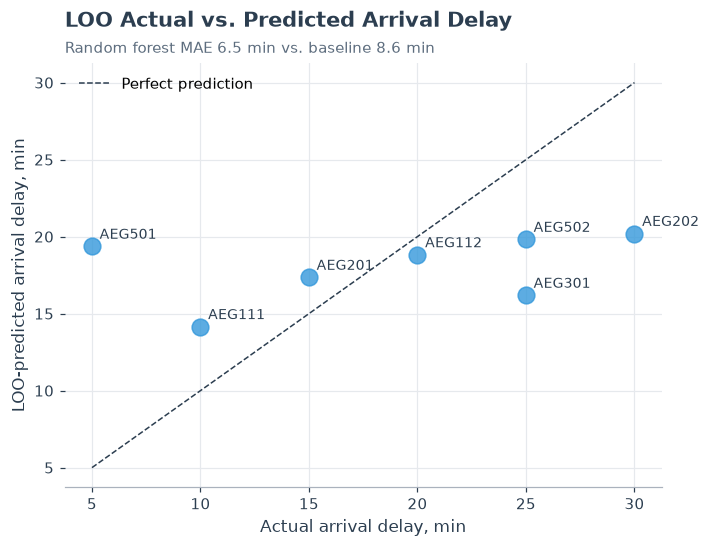

In [27]:
fig, ax = plt.subplots(figsize=(7, 5))
ax.scatter(ml_df["arr_delay_min"], ml_df["pred_arr_delay_loo"], s=120, color=BLUE, alpha=0.8)
lo = min(ml_df["arr_delay_min"].min(), ml_df["pred_arr_delay_loo"].min())
hi = max(ml_df["arr_delay_min"].max(), ml_df["pred_arr_delay_loo"].max())
ax.plot([lo, hi], [lo, hi], linestyle="--", color=TEXT, linewidth=1, label="Perfect prediction")
for _, row in ml_df.iterrows():
    ax.annotate(row["flight_no"], (row["arr_delay_min"], row["pred_arr_delay_loo"]),
                xytext=(5, 5), textcoords="offset points", fontsize=9, color=TEXT)
ax.grid(True, axis="both")
ax.set_xlabel("Actual arrival delay, min")
ax.set_ylabel("LOO-predicted arrival delay, min")
headline(ax, "LOO Actual vs. Predicted Arrival Delay",
         f"Random forest MAE {rf_mae:.1f} min vs. baseline {dummy_mae:.1f} min")
ax.legend(loc="upper left")
savefig(fig, "fig_11_ml_actual_vs_predicted.png")
plt.show()

In [28]:
clf_model = Pipeline([("preprocess", preprocess),
                      ("model", RandomForestClassifier(n_estimators=300, random_state=42, class_weight="balanced"))])

ml_df["pred_on_time_loo"] = cross_val_predict(clf_model, X, y_cls, cv=loo)
ml_df["baseline_on_time_loo"] = cross_val_predict(DummyClassifier(strategy="most_frequent"), X, y_cls, cv=loo)

rf_acc = accuracy_score(y_cls, ml_df["pred_on_time_loo"])
dummy_acc = accuracy_score(y_cls, ml_df["baseline_on_time_loo"])
print(f"LOO accuracy, random forest:        {rf_acc:.2f}")
print(f"LOO accuracy, majority baseline:    {dummy_acc:.2f}")

ml_df[["flight_no", "route", "arr_delay_min", "on_time_arrival_15", "pred_on_time_loo", "baseline_on_time_loo"]]

LOO accuracy, random forest:        0.86
LOO accuracy, majority baseline:    0.57


,flight_no,route,arr_delay_min,on_time_arrival_15,pred_on_time_loo,baseline_on_time_loo
0,AEG111,MUC–GVA,10.0,1,1,0
1,AEG112,GVA–MUC,20.0,0,0,0
2,AEG201,MUC–PMI,15.0,1,1,0
3,AEG202,PMI–MUC,30.0,0,0,0
4,AEG501,MUC–AMS,5.0,1,1,0
5,AEG502,AMS–MUC,25.0,0,0,0
6,AEG301,MUC–CPH,25.0,0,1,0


## 11. Key findings

In [29]:
worst = df.loc[df["arr_delay_min"].idxmax()]
top_cost = cost_summary.index[0]
print(f"1. Punctuality: {df['on_time_arrival_15'].sum()}/{len(df)} flights on time (≤15 min). "
      f"Worst: {worst['flight_no']} {worst['route']} at +{worst['arr_delay_min']:.0f} min.")
print(f"2. Propagation: {total_forced_delay:.0f} of {total_next_dep_delay:.0f} min of next-leg departure delay "
      f"({forced_share:.0%}) is structurally forced by late arrival + minGT. The rest is generated during the turnaround.")
print(f"   Most critical turn: {most_critical['turnaround']}.")
print(f"3. Connections: {int(conn['misconnected_pax'].sum())} of {int(conn['connex_pax'].sum())} connecting passengers "
      f"misconnect ({int(conn['misconnected'].sum())} of {len(conn)} connections).")
print(f"4. Cost: ≈ €{total_rotation_cost:,.0f} per rotation-day. Largest driver: {top_cost} "
      f"(€{cost_summary.iloc[0]:,.0f}). Upper-bound fleet proxy ≈ €{annual_network_cost / 1e9:.1f}bn per year.")
print(f"5. COO +10 min: {absorbed_min:.0f} of {added_buffer_min:.0f} added minutes absorb delay "
      f"({turns_benefiting} of {len(scenario)} turns), net {eur(scenario_net_impact)} per rotation-day.")
print("   A blanket buffer is too blunt. Target the tight turns and fix turnaround-generated delay instead.")
print(f"6. ML: random-forest LOO MAE {rf_mae:.1f} min vs. baseline {dummy_mae:.1f} min. "
      f"The pipeline is ready, but the data is far too small to support a model.")

1. Punctuality: 3/7 flights on time (≤15 min). Worst: AEG202 PMI–MUC at +30 min.
2. Propagation: 25 of 120 min of next-leg departure delay (21%) is structurally forced by late arrival + minGT. The rest is generated during the turnaround.
   Most critical turn: AEG502 → AEG301.
3. Connections: 59 of 128 connecting passengers misconnect (9 of 18 connections).
4. Cost: ≈ €62,707 per rotation-day. Largest driver: Direct pax delay (€19,950). Upper-bound fleet proxy ≈ €6.9bn per year.
5. COO +10 min: 15 of 60 added minutes absorb delay (2 of 6 turns), net −€1,275 per rotation-day.
   A blanket buffer is too blunt. Target the tight turns and fix turnaround-generated delay instead.
6. ML: random-forest LOO MAE 6.5 min vs. baseline 8.6 min. The pipeline is ready, but the data is far too small to support a model.


## 12. Limitations and the path to a production model

**Limitations of this analysis:** a single aircraft-day, so there is no variance estimate; a simplified cost model; MCT based on
scheduled outbound departure (ignores outbound delay that could save a connection); linear fleet scaling.

**A production delay model would need**
* 12–24 months of flight history at tail-number level (aircraft type and age),
* airport congestion, weather, ATC restrictions, gate/stand changes,
* crew legality and crew connections, maintenance events,
* passenger and baggage connection volumes, bank structure, itinerary value and rebooking alternatives,
* previous-leg delay as an explicit propagation feature.

**High-value prediction targets:** expected arrival delay · P(delay > 15 min) · P(misconnection) · expected delay cost ·
expected propagation to the next leg · **recommended buffer per turnaround / hub bank**, which turns the COO question into an optimisation.